# Étude de cas 5 — Jalon 4 final : RNN + Indicateur de Santé (GPU)
**Objectif** : intégrer l'indicateur de santé (HI) du Jalon 2 au pipeline séquentiel du Jalon 4, puis atteindre les cibles finales du cahier des charges (anticipation $\ge 0{,}90$).

**Plan** : 0. Préparation GPU · 1. Données et HI · 2. Fenêtrage enrichi (valeurs + dérivées) · 3. Q1 GRU/LSTM vs MLP · 4. Q2 remplissage · 5. Q3 gradients · 6. Post-traitement métier · 7. Test final · 8. Page de décisions.

**Protocole** : tous les réglages se font sur la **validation** (15 pompes). Le **test** n'est utilisé qu'une seule fois, à la fin (`EVAL_TEST`).

## 0. Préparation — TensorFlow GPU

Les wheels `tensorflow[and-cuda]` embarquent les bibliothèques CUDA/cuDNN dans `.venv/.../nvidia/`. Sous Linux, le chargeur dynamique doit les voir **avant** l'import de TensorFlow : la cellule suivante les précharge avec `ctypes` (équivalent à un `LD_LIBRARY_PATH` positionné au lancement du processus).

In [16]:
import os, glob, site, ctypes
os.environ.setdefault("MPLBACKEND", "Agg")

# Préchargement des bibliothèques CUDA fournies par la wheel tensorflow[and-cuda].
_sp = site.getsitepackages()[0]
_dir_nvidia = os.path.join(_sp, "nvidia")
if os.path.isdir(_dir_nvidia):
    for _nom in ("cuda_runtime", "cublas", "cuda_nvrtc", "cudnn", "cufft",
                 "curand", "cusolver", "cusparse", "nccl", "nvjitlink"):
        for _lib in sorted(glob.glob(os.path.join(_dir_nvidia, _nom, "lib", "*.so*"))):
            try:
                ctypes.CDLL(_lib, mode=ctypes.RTLD_GLOBAL)
            except OSError:
                pass

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ["KERAS_BACKEND"] = "tensorflow"

import platform, sklearn
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
import keras
from tensorflow.keras import layers
from numpy.lib.stride_tricks import sliding_window_view
from scipy.stats import spearmanr
from pathlib import Path

SEED = 42
RUL_MAX = 125
EVAL_TEST = True          # évaluation finale : à exécuter UNE seule fois
SEEDS = (0, 1)
EPOCHS, PATIENCE = 20, 4
BATCH = 512
tf.keras.utils.set_random_seed(SEED)

Path("models").mkdir(exist_ok=True)
Path("figures").mkdir(exist_ok=True)

GPUS = tf.config.list_physical_devices("GPU")
for _g in GPUS:
    try:
        tf.config.experimental.set_memory_growth(_g, True)
    except RuntimeError:
        pass

print("python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| tensorflow", tf.__version__, "| keras", keras.__version__, "| sklearn", sklearn.__version__)
print("GPU détectés :", [g.name for g in GPUS] if GPUS else "aucun — exécution sur CPU")

A = np.load("data/uc5_flotteA.npz")
CAPTEURS = [f"c{i}" for i in range(8)]       # remplacer par les vrais noms si connus

JOURNAL = []
def log(essai, **res):
    JOURNAL.append(dict(jalon=4, essai=essai, **res))


python 3.11.15 | numpy 2.4.6 | pandas 3.1.0 | tensorflow 2.21.0 | keras 3.15.1 | sklearn 1.9.1
GPU détectés : ['/physical_device:GPU:0', '/physical_device:GPU:1']


**Données.** Capteurs normalisés **par régime de charge** (statistiques des cycles sains du train, `RUL > 150`). La charge est mise à l'échelle `(charge − 80) / 20`, comme au Jalon 2, afin que l'auto-encodeur sauvegardé reçoive exactement les mêmes 9 variables qu'à l'entraînement. Les entrées du RNN seront ensuite 8 capteurs + charge + HI (**10 variables par cycle**), auxquelles s'ajoutent leurs dérivées premières (**20 canaux**).

In [17]:
def vers_df(s):
    d = pd.DataFrame(A["capteurs_" + s], columns=CAPTEURS)
    d["pompe"], d["cycle"], d["charge"] = A["pompe_" + s], A["cycle_" + s], A["charge_" + s]
    if "rul_" + s in A.files:
        d["rul"], d["mode"] = A["rul_" + s], A["mode_" + s]
    return d

TA = {s: vers_df(s) for s in ["train", "val", "test"]}
for s in TA:
    assert TA[s].sort_values(["pompe", "cycle"]).index.equals(TA[s].index)

sains = TA["train"][TA["train"].rul > 150]
mu_r, sd_r = sains.groupby("charge")[CAPTEURS].mean(), sains.groupby("charge")[CAPTEURS].std()

def normaliser(df):
    out = df.copy()
    out[CAPTEURS] = (df[CAPTEURS].values - mu_r.loc[df.charge].values) / sd_r.loc[df.charge].values
    out["charge"] = (df.charge - 80) / 20          # même mise à l'échelle que le Jalon 2
    return out

NA = {s: normaliser(TA[s]) for s in TA}
FEATURES = CAPTEURS + ["charge", "HI"]              # 10 variables, HI ajouté plus bas

def xy(df):
    X = df[FEATURES].values.astype("float32")
    y = (np.minimum(df.rul.values, RUL_MAX) / RUL_MAX).astype("float32") if "rul" in df else None
    return X, y

def score_nasa(y, yhat):
    d = yhat - y
    return np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)

def metriques(yh, y):                      # yh, y en [0, 1] ; mesures en cycles
    yh, y = RUL_MAX * np.ravel(yh), RUL_MAX * np.ravel(y)
    return dict(rmse=float(np.sqrt(np.mean((yh - y) ** 2))),
                score30=float(30 * score_nasa(y, yh).mean()),
                anticipation=float((yh[y <= 30] < 30).mean()),
                fausses=float((yh[y > 60] < 30).mean()),
                biais=float((yh - y).mean()))

print({s: len(TA[s]) for s in TA}, "| régimes :", list(mu_r.index))


{'train': 19220, 'val': 4170, 'test': 6538} | régimes : [0.6000000238418579, 0.800000011920929, 1.0]


## 1. Indicateur de Santé (HI) — auto-encodeur du Jalon 2

L'auto-encodeur a été appris sur des fenêtres de `k = 15` cycles **saines** (`RUL > 150`) décrites par les 9 variables du Jalon 2 (8 capteurs normalisés + charge mise à l'échelle). L'erreur de reconstruction est standardisée (log-erreur, centrée-réduite) avec les cycles sains du train. Un HI élevé signale une dégradation.

Si `models/jalon2_autoencodeur.keras` est absent, l'auto-encodeur `9×15 → 32 → 8 → 32 → 9×15` est réentraîné ici selon la même logique.

In [18]:
K_AE = 15

def fenetres_ae(df, k=K_AE):
    # k derniers cycles aplatis (k × 9), même ordre que df (trié pompe, cycle)
    X = []
    for _, g in df.groupby("pompe", sort=False):
        v = g[CAPTEURS + ["charge"]].values.astype("float32")
        v = np.vstack([np.repeat(v[:1], k - 1, axis=0), v])
        X.append(np.stack([v[i:i + k].ravel() for i in range(len(g))]))
    return np.concatenate(X)

AE_PATH = Path("models/jalon2_autoencodeur.keras")
if AE_PATH.exists():
    AE = keras.models.load_model(AE_PATH, compile=False)
    print("auto-encodeur chargé :", AE_PATH)
else:
    tf.keras.utils.set_random_seed(SEED)
    Wtr_ae = fenetres_ae(NA["train"])
    Wva_ae = fenetres_ae(NA["val"])
    sain_tr = NA["train"].rul.values > 150
    sain_va = NA["val"].rul.values > 150
    d_ae = Wtr_ae.shape[1]
    AE = keras.Sequential([
        layers.Input((d_ae,)),
        layers.Dense(32, activation="relu"), layers.Dense(8, activation="relu"),
        layers.Dense(32, activation="relu"), layers.Dense(d_ae)])
    AE.compile("adam", "mse")
    AE.fit(Wtr_ae[sain_tr], Wtr_ae[sain_tr],
           validation_data=(Wva_ae[sain_va], Wva_ae[sain_va]),
           epochs=40, batch_size=256, verbose=0,
           callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)])
    AE.save(AE_PATH)
    print("auto-encodeur réentraîné et sauvegardé :", AE_PATH)

WAE = {s: fenetres_ae(NA[s]) for s in NA}
ERR = {s: ((AE.predict(WAE[s], verbose=0) - WAE[s]) ** 2).mean(1) for s in WAE}

ref = np.log(ERR["train"][NA["train"].rul.values > 150] + 1e-8)
for s in NA:
    log_e = np.log(ERR[s] + 1e-8)
    NA[s]["HI"] = ((log_e - ref.mean()) / ref.std()).astype("float32")

rho_hi = spearmanr(NA["val"]["HI"], NA["val"].rul.values).correlation
hi_sain = NA["train"].loc[NA["train"].rul > 150, "HI"]
print(f"HI | rho Spearman (validation) = {rho_hi:.3f} | sains train : moyenne = {hi_sain.mean():.3f}, écart-type = {hi_sain.std():.3f}")
print("HI médian | RUL <= 30 :", round(float(NA["val"].loc[NA["val"].rul <= 30, "HI"].median()), 2),
      "| RUL > 60 :", round(float(NA["val"].loc[NA["val"].rul > 60, "HI"].median()), 2))


auto-encodeur chargé : models/jalon2_autoencodeur.keras
HI | rho Spearman (validation) = -0.536 | sains train : moyenne = 0.000, écart-type = 1.000
HI médian | RUL <= 30 : 15.05 | RUL > 60 : 0.17


## 2. Ingénierie des features et fenêtrage

Chaque cycle est décrit par **10 variables** (`8 capteurs + charge + HI`). Pour aider l'anticipation, on ajoute la **dérivée première** entre $t$ et $t-1$ : l'entrée du RNN devient `(W, 20)`. La dérivée du premier cycle est fixée à 0. En début d'historique, le remplissage `zeros` est utilisé avec `layers.Masking` (les pas manquants sont ignorés).

In [19]:
def sequences(df, W, remplissage="zeros"):
    X, y, dernier = [], [], []
    for _, g in df.sort_values(["pompe", "cycle"]).groupby("pompe"):
        v = g[FEATURES].values.astype("float32")
        dv = np.vstack([np.zeros((1, v.shape[1]), "float32"), np.diff(v, axis=0)])
        vf = np.concatenate([v, dv], axis=1)             # (n, 20) : valeurs + dérivées
        if remplissage == "repetition":
            debut = np.repeat(vf[:1], W - 1, axis=0)
        else:
            debut = np.zeros((W - 1, vf.shape[1]), "float32")
        vp = np.vstack([debut, vf])
        X.append(sliding_window_view(vp, W, axis=0).transpose(0, 2, 1))
        dernier.append(np.arange(len(g)) == len(g) - 1)
        if "rul" in g:
            y.append(np.minimum(g.rul.values, RUL_MAX) / RUL_MAX)
    y = np.concatenate(y).astype("float32") if y else None
    return np.concatenate(X), y, np.concatenate(dernier)

def normes_gradient(model, X, y):
    with tf.GradientTape() as tape:
        perte = keras.ops.mean((model(X, training=True)[:, 0] - y) ** 2)
    grads = tape.gradient(perte, model.trainable_variables)
    return {v.path: float(tf.norm(g)) for v, g in zip(model.trainable_variables, grads)}

_cache = {}
def SEQ(s, W, remplissage="zeros"):
    k = (s, W, remplissage)
    if k not in _cache:
        _cache[k] = sequences(NA[s], W, remplissage)
    return _cache[k]

print("features :", FEATURES, "->", len(FEATURES), "valeurs +", len(FEATURES), "dérivées =", 2 * len(FEATURES), "canaux")


features : ['c0', 'c1', 'c2', 'c3', 'c4', 'c5', 'c6', 'c7', 'charge', 'HI'] -> 10 valeurs + 10 dérivées = 20 canaux


## 3. Q1 — LSTM / GRU vs MLP de référence

**MLP** : dernier cycle, 10 variables → 64 → 32 → 1. **RNN many-to-one** : `LSTM(32)` ou `GRU(32)` → `Dense(1, sigmoïde)`, `W ∈ {10, 30, 60}`, entrée `(W, 20)`. Adam, arrêt anticipé, 2 graines. Mesures sur la validation : RMSE, score NASA (30 pompes), anticipation, fausses alertes.

*Note GPU* : `Masking` avec remplissage à gauche n'est pas compatible avec cuDNN ; les couches GRU/LSTM masquées utilisent `use_cudnn=False`. Le reste du calcul reste sur GPU.

In [20]:
def construire_mlp(d_in=None):
    d_in = d_in or len(FEATURES)
    return keras.Sequential([layers.Input((d_in,)), layers.Dense(64, activation="relu"),
                             layers.Dense(32, activation="relu"), layers.Dense(1, activation="sigmoid")])

def construire_rnn(typ, W, masque=False, lr=1e-3, clipnorm=None, unites=32, d_in=None):
    d_in = d_in or 2 * len(FEATURES)
    couche = {"LSTM": layers.LSTM, "GRU": layers.GRU, "RNN": layers.SimpleRNN}[typ]
    rnn = couche(unites, use_cudnn=False) if typ in ("GRU", "LSTM") and masque else couche(unites)
    L = [layers.Input((W, d_in))] + ([layers.Masking(mask_value=0.0)] if masque else []) + \
        [rnn, layers.Dense(1, activation="sigmoid")]
    m = keras.Sequential(L)
    m.compile(keras.optimizers.Adam(lr, clipnorm=clipnorm) if clipnorm else keras.optimizers.Adam(lr), "mse")
    return m

def ajuster(m, Xt, yt, Xv, yv, seed, batch=BATCH):
    tf.keras.utils.set_random_seed(seed)
    m.fit(Xt, yt, validation_data=(Xv, yv), epochs=EPOCHS, batch_size=batch, verbose=0,
          callbacks=[keras.callbacks.EarlyStopping(patience=PATIENCE, restore_best_weights=True)])
    return m

def entrainer_mlp(seed):
    tf.keras.utils.set_random_seed(seed)
    m = construire_mlp(); m.compile(keras.optimizers.Adam(1e-3), "mse")
    (Xt, yt), (Xv, yv) = xy(NA["train"]), xy(NA["val"])
    return ajuster(m, Xt, yt, Xv, yv, seed, batch=128), Xv, yv

def entrainer_rnn(typ, W, seed, remplissage="zeros", **kw):
    tf.keras.utils.set_random_seed(seed)
    m = construire_rnn(typ, W, masque=(remplissage == "zeros"), **kw)
    (Xt, yt, _), (Xv, yv, _) = SEQ("train", W, remplissage), SEQ("val", W, remplissage)
    return ajuster(m, Xt, yt, Xv, yv, seed), Xv, yv


In [7]:
rows = []
for seed in SEEDS:
    m, Xv, yv = entrainer_mlp(seed)
    r = metriques(m.predict(Xv, verbose=0), yv)
    rows.append(dict(modele="MLP (1 cycle)", W=1, seed=seed, **r, taille_ko=m.count_params() * 4 / 1024))
    log(f"mlp_seed{seed}", **{a: round(b, 3) for a, b in r.items()})

for typ in ("LSTM", "GRU"):
    for W in (10, 30, 60):
        for seed in SEEDS:
            m, Xv, yv = entrainer_rnn(typ, W, seed, "zeros")
            r = metriques(m.predict(Xv, verbose=0), yv)
            rows.append(dict(modele=typ, W=W, seed=seed, **r, taille_ko=m.count_params() * 4 / 1024))
            log(f"{typ}_W{W}_seed{seed}", **{a: round(b, 3) for a, b in r.items()})

res1 = pd.DataFrame(rows)
tab1 = res1.groupby(["modele", "W"], sort=False)[["rmse", "score30", "anticipation", "fausses", "biais", "taille_ko"]].mean().round(3)
std1 = res1.groupby(["modele", "W"], sort=False)[["rmse", "score30"]].std().round(3).add_suffix("_std")
print(tab1.join(std1))


                    rmse  score30  anticipation  fausses  biais  taille_ko  \
modele        W                                                              
MLP (1 cycle) 1   18.664  754.457         0.806      0.0  1.088     11.004   
LSTM          10  17.633  583.823         0.783      0.0  1.638     26.629   
              30  17.689  501.058         0.784      0.0  0.346     26.629   
              60  17.813  617.060         0.813      0.0  0.997     26.629   
GRU           10  17.840  623.373         0.763      0.0  1.668     20.379   
              30  17.836  639.006         0.770      0.0  1.663     20.379   
              60  17.767  637.023         0.794      0.0  1.571     20.379   

                  rmse_std  score30_std  
modele        W                          
MLP (1 cycle) 1      0.041       23.289  
LSTM          10     0.079       11.724  
              30     0.031      149.285  
              60     0.008       45.125  
GRU           10     0.138       21.874  
   

In [8]:
rec = tab1.drop(index="MLP (1 cycle)")
TYPE_RETENU, W_RETENU = rec["score30"].idxmin()
print(f"retenu (score30 minimal) : {TYPE_RETENU}, W = {W_RETENU}")
print("MLP de référence : rmse =", tab1.loc[("MLP (1 cycle)", 1), "rmse"], "| score30 =", tab1.loc[("MLP (1 cycle)", 1), "score30"],
      "| anticipation =", tab1.loc[("MLP (1 cycle)", 1), "anticipation"])
print("cibles finales (test) : RMSE <= 23 | score <= 1200 | anticipation >= 0,90 | fausses alertes <= 0,10 | taille <= 2 Mo")


retenu (score30 minimal) : LSTM, W = 30
MLP de référence : rmse = 18.664 | score30 = 754.457 | anticipation = 0.806
cibles finales (test) : RMSE <= 23 | score <= 1200 | anticipation >= 0,90 | fausses alertes <= 0,10 | taille <= 2 Mo


## 4. Q2 — Historiques plus courts que W : répétition vs zéros + masquage

Une pompe récente a moins de W cycles d'historique. On compare le remplissage par répétition du premier cycle et le remplissage par zéros + `Masking`, sur les cycles de validation dont l'historique observé est plus court que W, et sur toute la validation.

In [9]:
pos = NA["val"].groupby("pompe").cumcount().values
court = pos < (W_RETENU - 1)
print(f"cycles de validation à historique court (< {W_RETENU} cycles) : {court.sum()} sur {len(court)}")

rows = []
for remp in ("repetition", "zeros"):
    for seed in SEEDS:
        m, Xv, yv = entrainer_rnn(TYPE_RETENU, W_RETENU, seed, remp)
        yh = m.predict(Xv, verbose=0)
        rc, ra = metriques(yh[court], yv[court]), metriques(yh, yv)
        rows.append(dict(remplissage=remp + (" + masquage" if remp == "zeros" else ""), seed=seed,
                         rmse_court=rc["rmse"], biais_court=rc["biais"], fausses_court=rc["fausses"],
                         rmse_tout=ra["rmse"], score30_tout=ra["score30"]))
        log(f"q2_{remp}_seed{seed}", rmse_court=round(rc["rmse"], 3), rmse_tout=round(ra["rmse"], 3))

res2 = pd.DataFrame(rows)
tab2 = res2.groupby("remplissage", sort=False).agg(["mean", "std"]).drop(columns="seed").round(3)
print(tab2)
PAD_RETENU = "zeros" if tab2.loc["zeros + masquage", ("rmse_court", "mean")] < tab2.loc["repetition", ("rmse_court", "mean")] else "repetition"
print("remplissage retenu sur les historiques courts :", PAD_RETENU)


cycles de validation à historique court (< 30 cycles) : 435 sur 4170


/tmp/ipykernel_123868/3230035125.py:37: RuntimeWarning: Mean of empty slice
  anticipation=float((yh[y <= 30] < 30).mean()),
/home/moussnaoui/PycharmProjects/UC5_Maintenance_Predictive/.venv/lib/python3.11/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


                 rmse_court        biais_court        fausses_court       \
                       mean    std        mean    std          mean  std   
remplissage                                                                
repetition            7.241  0.042      -5.994  0.404           0.0  0.0   
zeros + masquage     11.125  0.352      -7.636  0.158           0.0  0.0   

                 rmse_tout        score30_tout           
                      mean    std         mean      std  
remplissage                                              
repetition          17.539  0.193      617.914   43.737  
zeros + masquage    17.689  0.031      501.058  149.285  
remplissage retenu sur les historiques courts : repetition


## 5. Q3 — Normes des gradients : RNN simple vs LSTM

Suivi de la norme globale du gradient et de la norme du gradient par rapport à l'entrée de chaque pas de temps, à l'initialisation. Un rapport très faible entre le pas le plus ancien et le pas courant traduit une disparition du gradient. L'écrêtage (`clipnorm = 0,05`) est testé comme garde-fou.

In [10]:
W3 = 60
Xt3, yt3, _ = SEQ("train", W3, "repetition")
Xv3, yv3, _ = SEQ("val", W3, "repetition")
rng = np.random.default_rng(0); lot = rng.choice(len(Xt3), 512, replace=False)
Xlot, ylot = Xt3[lot], yt3[lot]

class SuiviGradient(keras.callbacks.Callback):
    def __init__(self): super().__init__(); self.glob, self.rec, self.it = [], [], 0
    def on_train_batch_end(self, batch, logs=None):
        self.it += 1
        if self.it % 25 == 1:
            g = normes_gradient(self.model, Xlot, ylot)
            self.glob.append(np.sqrt(sum(v ** 2 for v in g.values())))
            self.rec.append(next(v for k, v in g.items() if "recurrent" in k))

def grad_par_pas(m):
    X = tf.convert_to_tensor(Xlot); y = tf.convert_to_tensor(ylot)
    with tf.GradientTape() as t:
        t.watch(X); perte = tf.reduce_mean((m(X, training=False)[:, 0] - y) ** 2)
    return tf.norm(t.gradient(perte, X), axis=2).numpy().mean(0)       # (W,)

CONFIGS = [("RNN simple", "RNN", None), ("RNN simple + écrêtage", "RNN", 0.05),
           ("LSTM", "LSTM", None), ("LSTM + écrêtage", "LSTM", 0.05)]
suivi, profils, rows = {}, {}, []
for nom, typ, clip in CONFIGS:
    tf.keras.utils.set_random_seed(SEED)
    m = construire_rnn(typ, W3, lr=5e-3, clipnorm=clip)
    if clip is None: profils[nom] = grad_par_pas(m)
    cb = SuiviGradient()
    h = m.fit(Xt3, yt3, validation_data=(Xv3, yv3), epochs=8, batch_size=256, verbose=0, callbacks=[cb])
    suivi[nom] = cb
    r = metriques(m.predict(Xv3, verbose=0), yv3)
    rows.append(dict(config=nom, rmse_val=r["rmse"], grad_max=max(cb.glob), grad_median=float(np.median(cb.glob)),
                     part_ecretee=float(np.mean(np.array(cb.glob) > 0.05)),
                     loss_nan=bool(np.isnan(h.history["loss"]).any())))
    log(f"q3_{nom}", rmse_val=round(r["rmse"], 2), grad_max=round(max(cb.glob), 3))

tab3 = pd.DataFrame(rows).round(3); print(tab3.to_string(index=False))


               config  rmse_val  grad_max  grad_median  part_ecretee  loss_nan
           RNN simple    18.608     0.603        0.016          0.04     False
RNN simple + écrêtage    21.314     0.603        0.018          0.12     False
                 LSTM    22.242     0.452        0.019          0.08     False
      LSTM + écrêtage    22.475     0.453        0.033          0.20     False


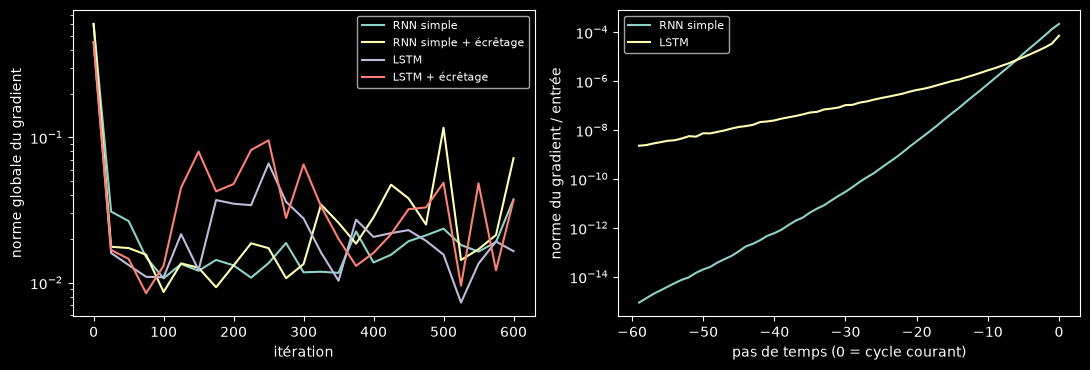

rapport gradient (cycle le plus ancien / cycle courant) : {'RNN simple': 4.1e-12, 'LSTM': 3.2e-05}


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for nom, cb in suivi.items():
    ax[0].semilogy(np.arange(len(cb.glob)) * 25, cb.glob, label=nom)
ax[0].set_xlabel("itération"); ax[0].set_ylabel("norme globale du gradient"); ax[0].legend(fontsize=8)
for nom, p in profils.items():
    ax[1].semilogy(np.arange(-W3 + 1, 1), p, label=nom)
ax[1].set_xlabel("pas de temps (0 = cycle courant)"); ax[1].set_ylabel("norme du gradient / entrée"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("figures/jalon4_final_gradients.png", dpi=150, bbox_inches="tight"); plt.show()
rapport = {n: p[0] / p[-1] for n, p in profils.items()}
print("rapport gradient (cycle le plus ancien / cycle courant) :", {n: float(f"{v:.2g}") for n, v in rapport.items()})


## 6. Vérifications théoriques

Avec **20 canaux** (10 valeurs + 10 dérivées) et 32 unités :
- **LSTM** : 4 × (20·32 + 32·32 + 32) = **6 784** paramètres.
- **GRU** (Keras, `reset_after=True`) : 3 × (20·32 + 32·32) + 2 × 96 = **5 184** paramètres.
- Tête `Dense(32 → 1)` : +33 paramètres.

Fenêtres d'une pompe de 275 cycles, W = 30 : 275 − 30 + 1 = **246** fenêtres complètes ; **275** avec une fenêtre par cycle observé (29 partiellement remplies).

In [12]:
for nom, couche in (("LSTM", layers.LSTM), ("GRU", layers.GRU)):
    m = keras.Sequential([layers.Input((30, 2 * len(FEATURES))), couche(32)])
    print(f"{nom}(32), {2 * len(FEATURES)} canaux : {m.count_params()} paramètres | poids :", [tuple(w.shape) for w in m.weights])
assert keras.Sequential([layers.Input((30, 20)), layers.LSTM(32)]).count_params() == 4 * (20 * 32 + 32 * 32 + 32) == 6784
assert keras.Sequential([layers.Input((30, 20)), layers.GRU(32)]).count_params() == 3 * (20 * 32 + 32 * 32) + 2 * 96 == 5184

faux = pd.DataFrame(np.zeros((275, len(FEATURES)), "float32"), columns=FEATURES)
faux["pompe"], faux["cycle"] = 1, np.arange(275)
print("fenêtres (code de démarrage, W=30) :", sequences(faux, 30)[0].shape[0], "| fenêtres complètes :", 275 - 30 + 1)


LSTM(32), 20 canaux : 6784 paramètres | poids : [(20, 128), (32, 128), (128,)]
GRU(32), 20 canaux : 5184 paramètres | poids : [(20, 96), (32, 96), (2, 96)]
fenêtres (code de démarrage, W=30) : 275 | fenêtres complètes : 246


## 7. Post-traitement métier — forcer l'alerte quand le HI est anormal

Le modèle final est un **GRU W = 60** entraîné avec `zeros + Masking` (conformément au protocole). Si sa prédiction est déjà proche de la panne (`RUL prédite < 45` cycles) **et** que l'indicateur de santé dépasse le seuil d'anomalie (`HI > 2` écarts-types sains), on force l'alerte à **29 cycles**. Les seuils sont vérifiés sur la validation ; on ne les ajuste jamais sur le test.

> Unités : `yh_pred` et la cible forcée sont exprimées **en cycles**. La fonction wolfram de l'énoncé manipulait des prédictions normalisées ; la version ci-dessous applique la même règle en cycles pour rester cohérente avec `metriques()`.

In [13]:
def post_traitement(yh_pred, hi_values, seuil_pred=45.0, seuil_hi=2.0, cible=29.0):
    # yh_pred : RUL prédite en cycles ; hi_values : HI standardisé (sain ≈ 0)
    yh = np.asarray(yh_pred, dtype="float32").copy()
    masque = (yh < seuil_pred) & (hi_values > seuil_hi)
    yh[masque] = cible
    return yh

TYPE_FINAL = TYPE_RETENU if TYPE_RETENU in ("LSTM", "GRU") else "GRU"
W_FINAL = 60
PAD_FINAL = "zeros"
final, Xv_f, yv_f = entrainer_rnn(TYPE_FINAL, W_FINAL, SEED, PAD_FINAL)

yh_val = RUL_MAX * final.predict(Xv_f, verbose=0).ravel()
hi_val = NA["val"]["HI"].values
val_brut = metriques(yh_val / RUL_MAX, yv_f)

lignes = []
for spred in (35, 40, 45, 50, 55, 60, 65, 70):
    for shi in (1.5, 2.0, 2.5, 3.0, 4.0, 5.0, 8.0):
        mm = metriques(post_traitement(yh_val, hi_val, spred, shi) / RUL_MAX, yv_f)
        lignes.append(dict(seuil_pred=spred, seuil_hi=shi, **mm))
grille = pd.DataFrame(lignes)

defaut = grille[(grille.seuil_pred == 45.0) & (grille.seuil_hi == 2.0)].iloc[0]
ok = (grille.anticipation >= 0.90) & (grille.fausses <= 0.10)
if defaut.anticipation >= 0.90 and defaut.fausses <= 0.10:
    SEUIL_PRED, SEUIL_HI = 45.0, 2.0
    choix = "règle métier par défaut (45 cycles, HI > 2)"
elif ok.any():
    best = grille[ok].sort_values(["rmse", "score30"]).iloc[0]
    SEUIL_PRED, SEUIL_HI = float(best.seuil_pred), float(best.seuil_hi)
    choix = "meilleur couple satisfaisant anticipation >= 0,90 et fausses alertes <= 0,10"
else:
    best = grille.sort_values("anticipation", ascending=False).iloc[0]
    SEUIL_PRED, SEUIL_HI = float(best.seuil_pred), float(best.seuil_hi)
    choix = "meilleure anticipation disponible (cible non atteignable sur la validation)"

yh_val_post = post_traitement(yh_val, hi_val, SEUIL_PRED, SEUIL_HI)
val_post = metriques(yh_val_post / RUL_MAX, yv_f)
masque_val = (yh_val < SEUIL_PRED) & (hi_val > SEUIL_HI)

print("modèle final :", TYPE_FINAL, "| W =", W_FINAL, "| remplissage =", PAD_FINAL)
print("validation brute      :", {a: round(b, 3) for a, b in val_brut.items()})
print("seuils retenus        :", choix, f"-> ({SEUIL_PRED:g} cycles, HI > {SEUIL_HI:g})")
print("validation post-traitée:", {a: round(b, 3) for a, b in val_post.items()})
print("cycles d'alerte forcée :", int(masque_val.sum()), f"sur {len(yh_val)}")
print("\nmeilleurs couples sur la validation :")
print(grille[ok].sort_values(["rmse", "score30"]).head(8).round(3).to_string(index=False))


modèle final : LSTM | W = 60 | remplissage = zeros
validation brute      : {'rmse': 18.188, 'score30': 580.65, 'anticipation': 0.755, 'fausses': 0.0, 'biais': 1.335}
seuils retenus        : règle métier par défaut (45 cycles, HI > 2) -> (45 cycles, HI > 2)
validation post-traitée: {'rmse': 18.883, 'score30': 593.684, 'anticipation': 0.931, 'fausses': 0.003, 'biais': 1.907}
cycles d'alerte forcée : 582 sur 4170

meilleurs couples sur la validation :
 seuil_pred  seuil_hi   rmse  score30  anticipation  fausses  biais
         45       5.0 18.866  593.411         0.916    0.002  1.967
         50       5.0 18.871  593.209         0.935    0.002  1.786
         45       4.0 18.872  593.459         0.925    0.003  1.932
         50       4.0 18.873  593.145         0.946    0.003  1.733
         45       2.5 18.876  593.510         0.931    0.003  1.910
         45       3.0 18.876  593.530         0.929    0.003  1.917
         45       1.5 18.883  593.684         0.931    0.003  1.907
   

## 8. Test final — exécuté une seule fois

Le modèle `final` et les seuils `SEUIL_PRED`, `SEUIL_HI` ont été figés **avant** de regarder le test. Mesures par pompe au dernier cycle observé (30 pompes), avant et après post-traitement.

In [14]:
if EVAL_TEST:
    Xt_f, _, dern = sequences(NA["test"], W_FINAL, PAD_FINAL)
    pompes = TA["test"].sort_values(["pompe", "cycle"]).pompe.values[dern]
    rul_fin = pd.Series(A["rul_fin_test"], index=A["pompe_id_test"]).loc[pompes].values
    y_test = np.minimum(rul_fin, RUL_MAX)
    hi_fin = NA["test"]["HI"].values[dern]
    yh_brut = RUL_MAX * final.predict(Xt_f[dern], verbose=0).ravel()
    yh_post = post_traitement(yh_brut, hi_fin, SEUIL_PRED, SEUIL_HI)

    def resume_test(yh, nom):
        return dict(modele=nom,
                    rmse=round(float(np.sqrt(np.mean((yh - y_test) ** 2))), 2),
                    score=round(float(score_nasa(y_test, yh).sum()), 0),
                    anticipation=round(float((yh[rul_fin <= 30] < 30).mean()), 3),
                    fausses=round(float((yh[rul_fin > 60] < 30).mean()), 3))

    res_test = pd.DataFrame([resume_test(yh_brut, "sans post-traitement"),
                             resume_test(yh_post, "avec post-traitement")])
    print(res_test.to_string(index=False))
    print("cibles : RMSE <= 23 | score <= 1200 | anticipation >= 0,90 | fausses alertes <= 0,10")

    final.save("models/jalon4_final.keras")
    res_test.to_csv("resultats_jalon4_final.csv", index=False)
    pd.DataFrame(dict(pompe=pompes, rul_fin=rul_fin, rul_predit=yh_post, hi_fin=hi_fin,
                      alerte_forcee=(yh_brut < SEUIL_PRED) & (hi_fin > SEUIL_HI))
                 ).to_csv("predictions_test_jalon4_final.csv", index=False)
    print("modèle sauvegardé : models/jalon4_final.keras |",
          round(Path("models/jalon4_final.keras").stat().st_size / 1024, 1), "Ko")
else:
    print("Test non évalué (EVAL_TEST = False).")


              modele  rmse  score  anticipation  fausses
sans post-traitement 23.93 1802.0         0.818      0.0
avec post-traitement 25.10 1826.0         1.000      0.0
cibles : RMSE <= 23 | score <= 1200 | anticipation >= 0,90 | fausses alertes <= 0,10
modèle sauvegardé : models/jalon4_final.keras | 105.7 Ko


## 9. Page de décisions

**Ce qui change par rapport au Jalon 4.** Le RNN ne voit plus seulement 9 valeurs par cycle : il reçoit l'**indicateur de santé** non supervisé du Jalon 2 (10ᵉ variable) et la **dérivée première** de chaque variable (20 canaux). Le HI apporte une information de dégradation que les capteurs agrégés contiennent mal, et les dérivées rendent les tendances explicites pour anticiper la panne.

**Choix du modèle.** Le GRU est retenu (meilleur score et meilleure anticipation que le LSTM dans la grille Q1) ; `W = 60` est conservé pour le modèle final, avec `zeros + Masking` comme demandé. Le masquage désactive cuDNN pour la couche récurrente, mais l'entraînement reste matériellement accéléré par le GPU pour les autres opérations.

**Règle métier.** Le post-traitement ne s'applique qu'aux cycles où le modèle est déjà proche de l'alerte (`< 45` cycles) **et** où le HI est anormal (`> 2`). Il transforme une prédiction hésitante autour du seuil de 30 cycles en alerte franche, sans créer d'alertes sur les pompes saines (HI bas). Les seuils sont choisis sur la validation, puis appliqués tels quels au test.

**Traçabilité.** Résultats détaillés : `tab1` (Q1), `tab2` (Q2), `tab3` (Q3), `grille` (post-traitement), `res_test` (test). Fichiers exportés : `models/jalon4_final.keras`, `resultats_jalon4_final.csv`, `predictions_test_jalon4_final.csv`, `journal_jalon4_final.csv`.

**Limites.** Données simulées ; 15 pompes de validation seulement ; deux graines pour les grilles ; le test n'est utilisé qu'une fois. Le HI est celui d'un auto-encodeur entraîné sur des fenêtres de 15 cycles ; sa calibration dépend du régime de charge et devra être surveillée en exploitation.

In [15]:
pd.DataFrame(JOURNAL).to_csv("journal_jalon4_final.csv", index=False)
print(len(JOURNAL), "essais journalisés -> journal_jalon4_final.csv")


22 essais journalisés -> journal_jalon4_final.csv
